# РЕГРЕССИЯ, ФАКТОРНЫЙ АНАЛИЗ, SEM

В этом занятии мы рассмотрим пять методов машинного обучения: 

- Линейная регрессия 
- Полиноминальная регрессия 
- Эксплораторный факторный анализ 
- Конфирматорный факторный анализ 
- Путевой анализ (Structural equation model, SEM)

Датасет: https://www.kaggle.com/datasets/miroslavsabo/young-people-survey?resource=download&select=responses.csv 

## Подготовка

In [1]:
 #import libraries
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import sklearn

In [2]:
df = pd.read_csv('YPS.csv') 
df = df.dropna()

Зависимой переменной в линейной регрессии может быть только количественная переменная. Создадим переменную "общие траты", как сумму всех трат

In [3]:
df['Summa'] = df['Branded clothing'] + df['Entertainment spending'] + df['Spending on looks'] + df['Spending on gadgets']

Предикторами будут возраст и одиночество 

In [4]:
from sklearn.model_selection import train_test_split
y = df['Summa']   
X = df[['Age', 'Loneliness']]   
X_train, X_test, y_train, y_test = train_test_split(X, y)

## Линейная регрессия 

### Способ 1: LinearRegression в Sklearn 

Линейная регрессия в Sklearn: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

Параметры линейной регрессии (источник: https://proglib.io/p/linear-regression?ysclid=lq0pmx4mpd290949493): 

- fit_intercept – логический (True по умолчанию) параметр, который решает, вычислять отрезок b₀ (True) или рассматривать его как равный нулю (False)

- normalize – логический (False по умолчанию) параметр, который решает, нормализовать входные переменные (True) или нет (False)

- copy_X – логический (True по умолчанию) параметр, который решает, копировать (True) или перезаписывать входные переменные (False).

In [5]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)

In [6]:
model.score(X_train, y_train) #R-squared

0.017188743183810806

In [7]:
model.score(X_test, y_test)

0.03324916609878992

In [8]:
model.intercept_

14.489515639408928

In [9]:
model.coef_

array([-0.06055393, -0.39183344])

In [10]:
pred = model.predict(X_test)
pred

array([11.77165726, 11.83221119, 11.37982382, 12.61587807, 13.00771151,
       11.62203953, 12.1634907 , 11.77165726, 11.62203953, 12.04238285,
       12.1634907 , 12.04238285, 11.94978487, 12.10293677, 11.01650026,
       13.06826543, 11.07705419, 11.37982382, 12.22404463, 11.65054941,
       11.98182892, 11.98182892, 12.55532414, 11.80016714, 12.43421629,
       12.1634907 , 12.61587807, 12.1634907 , 12.04238285, 12.22404463,
       11.19816204, 12.49477021, 11.98182892, 11.46888762, 12.04238285,
       11.5614856 , 12.55532414, 11.71110333, 11.65054941, 12.49477021,
       12.37366236, 12.43421629, 12.94715758, 12.61587807, 12.43421629,
       11.61850535, 11.44037775, 12.22404463, 12.61587807, 12.28459856,
       11.98182892, 12.1634907 , 11.83221119, 12.73698592, 12.49477021,
       12.676432  , 11.71110333, 12.43421629, 11.77165726, 11.22667192,
       12.1634907 , 12.43421629, 12.01033879, 11.25871597, 12.1634907 ,
       12.1634907 , 12.49477021, 12.37366236, 12.37366236, 12.49

### Способ 2: OLS (Ordinary Least Squares) в statsmodels

OLS в statmodels: https://www.statsmodels.org/dev/generated/statsmodels.regression.linear_model.OLS.html

Модель OLS имеет особенность: она не учитывает константу при рассчете R-квадрат и коэффициентов. Чтобы модель выдала корректные результаты, необходимо добавить колонку с единицами в предикторы. 

Источник: https://stats.stackexchange.com/questions/146804/difference-between-statsmodel-ols-and-scikit-linear-regression

In [11]:
ones = np.ones(len(df))   #Создаем колонку с единицами 
df['ones'] = ones

In [12]:
y = df['Summa']    
X = df[['ones','Age', 'Loneliness']]

In [13]:
import statsmodels.api as sm
from scipy import stats
model = sm.OLS(y, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Summa   R-squared:                       0.022
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     7.600
Date:                Thu, 14 Dec 2023   Prob (F-statistic):           0.000545
Time:                        10:34:12   Log-Likelihood:                -1808.6
No. Observations:                 674   AIC:                             3623.
Df Residuals:                     671   BIC:                             3637.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
ones          15.2446      1.106     13.787      0.000      13.074      17.416
Age           -0.0911      0.050     -1.816      0.070      -0.190       0.007
Loneliness    -0.4241      0.119     -3.554      0.000      -0.658      -0.190
==============================================================================
Omnibus:                        1.031   Durbin-Watson:                   1.858
Prob(Omnibus):                  0.597   Jarque-Bera (JB):                1.064
Skew:                           0.020   Prob(JB):                        0.587
Kurtosis:                       2.809   Cond. No.                         168.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Метрики качества модели** 

- **R-squared** Процент дисперсии зависимой переменной, объясненный признаками, включенными в модель 

- **Adj. R-squared** Скорректированный R-квадрат. "Штрафует" за включение в модель "плохих" предикторов 

- **F-statistic** - критерий Фишера - статистика, значение которой необходимо для проверки гипотезы о равенстве дисперсий.

- **Prob. (F-statistic)** - вероятность того, что коэффициенты при всех переменных равны нулю (кроме интерсепта).

- **Log-likelihood** - насколько хорошо данные описываются моделью. Можно использовать для сравнения нескольких моделей. Чем больше значение, тем лучше. Абсолютные значения не интерпретируются 

- **AIC и BIC** - используются для сравнения моделей. Чем меньше значения, тем лучше. 

**Проверка допущений линейной регрессии**

- **Omnibus**: проверка нормальности распределения остатков (Допущение линейной регрессии - остатки распределены нормально) Значение 1 означает совершенно нормальное распределение (чем ближе к 1, тем лучше) 

- **Skew**: мера симметрии распределения остатков (Остатки должны быть распределены симметрично). Значение 0 означает полную симметрию (чем ближе к 0, тем лучше) 

- **Kurtosis (Эксцесс)** - измеряет остроту распределения остатков или его концентрацию около 0 на нормальной кривой. Более высокий эксцесс означает меньшее количество выбросов. (Чем выше, тем лучше) 

- **Durbin-Watson**: проверка, коррелируют ли остатки (Допущение линейной регрессии - остатки не коррелируют). Значения 1.2 - 2.5 считаются приемлемыми (лучше, если они от 1 до 2)

**Интерпретация результатов** 

- **Coef** - значение коэффициента при переменной 

- **Coef для единиц** - константа (предсказанное значение зависимой переменной, при условии, что все предикторы равны 0)

- **t** - T-критерий (на него можно не смотреть, на его основе рассчитывается p-value) 

- **P>T** - p-value, по нему оцениваем значимость предиктора 




Источник: https://habr.com/ru/articles/681218/ (В источнике объясняется математика, стоящая за критериями)



**Сравнение LinearRegression и OLS**

- LinearRegression позволяет предсказывать значения y. OLS предоставляет подробную информацию о качестве модели (значимость коэффициентов, результаты тестов). 

- LinearRegression имеет параметры, которые можно варьировать. OLS статична. 

- LinearRegression учитывает константу, а OLS - нет (решение: добавлять в OLS столбец с единицами)

**Вывод**: 

 - **LinearRegression** стоит использовать, когда цель - **предсказать** несуществующие значения. 
 
 - **OLS** стоит использовать, когда цель - **понять** взаимоотношения между зависимой переменной и предикторами 

## Полиноминальная регрессия 

Полиноминальная регрессия используется, если предполагается нелинейная связь между зависимой переменной и предикторами.
Пример статьи, где была найдена нелинейная (квадратичная) связь между числом друзей и психическим благополучием / когнитивными способностями школьников: https://elifesciences.org/articles/84072

Для реализации полиноминальной регрессии можно воспользоваться моделями линейной регрессии, только перед этим необходимо подготовить предикторы (возвести их в нужную степень). Для этого есть инструмент "PolynomialFeatures": https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html 

**Внимание**: 

- Чем сложнее модель (т.е. чем более высокие степени используются (параметр degree)), тем больше риска, что модель будет переобучена. Не стоит использовать, если нет теоретически обоснованного предположения о нелинейности связи 

- Когда много предикторов, может быть сложно разобраться, какой коэффициент к чему относится. Плюс повышается риск переобучения. Рекомендуется использовать минимум предикторов для полиноминальной регрессии 

In [30]:
y = df['Summa']   
X = df[['Age', 'Loneliness']]

In [31]:
from sklearn.preprocessing import PolynomialFeatures
quadratic = PolynomialFeatures(degree=2)
X_quad = quadratic.fit_transform(X)
model = LinearRegression()
model.fit(X_quad, y)

LinearRegression()

In [32]:
X_quad

array([[  1.,  20.,   3., 400.,  60.,   9.],
       [  1.,  19.,   2., 361.,  38.,   4.],
       [  1.,  20.,   5., 400., 100.,  25.],
       ...,
       [  1.,  18.,   4., 324.,  72.,  16.],
       [  1.,  25.,   3., 625.,  75.,   9.],
       [  1.,  21.,   3., 441.,  63.,   9.]])

In [21]:
model.score(X_quad, y)

0.005866188818732798

In [22]:
model.coef_

array([ 0.        , -0.71997972,  0.01455838])

Аналогично для построения можно использовать OLS (Столбик с единицами уже есть в X_quad)

In [33]:
model = sm.OLS(y, X_quad).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Summa   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     5.086
Date:                Thu, 14 Dec 2023   Prob (F-statistic):           0.000139
Time:                        10:49:31   Log-Likelihood:                -1803.5
No. Observations:                 674   AIC:                             3619.
Df Residuals:                     668   BIC:                             3646.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.8114      6.782      2.774      0.006       5.495      32.128
x1            -0.5001      0.567     -0.882      0.378      -1.613       0.613
x2             0.0975      1.069      0.091      0.927      -2.002       2.197
x3             0.0148      0.012      1.223      0.222      -0.009       0.039
x4            -0.0832      0.045     -1.857      0.064      -0.171       0.005
x5             0.1942      0.091      2.133      0.033       0.015       0.373
==============================================================================
Omnibus:                        0.599   Durbin-Watson:                   1.864
Prob(Omnibus):                  0.741   Jarque-Bera (JB):                0.698
Skew:                          -0.037   Prob(JB):                        0.706
Kurtosis:                       2.861   Cond. No.                     2.22e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.22e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Задание 1

- Постройте регрессию (OLS), которая будет предсказывать BMI (выбор предикторов - на ваше усмотрение) 
- Оцените метрики качества модели 
- Оцените, выполняются ли допущения логистической регрессии 
- Проинтерпретируйте результаты 
- Выдвинете гипотезу, может ли быть квадратичная связь BMI с одним из предикторов 
- Если да, постройте полиноминальную регрессию, оцените качество и проинтерпретируйте результаты 

In [34]:
df["BMI"] = (df["Weight"]/((df["Height"]*0.01)**2))

In [ ]:
#your code here 

## Эксплораторный факторный анализ

Попрбуем объединить в группы фильмы разных жанров (снизить размерность). Создадим датасет, в котором находятся только переменные, относящиеся к фильмам 

In [35]:
df['Fantasy'] = df['Fantasy/Fairy tales']
df['Sci'] = df['Sci-fi']

In [36]:
df_cfa = df[['Horror', 'Thriller', 'Comedy', 'Romantic', 'Sci', 'War', 'Fantasy', 'Animated', 'Documentary', 'Western', 'Action']]

### **Предварительный анализ данных**

**1) Тест Бартлетта на сферичность**

Тест Бартлетта на сферичность сравнивает наблюдаемую корреляционную матрицу с единичной матрицей. По сути, он проверяет, есть ли определенная избыточность между переменными, которые мы можем суммировать с помощью нескольких факторов. Т.е. насколько разумно проводить факторный анализ на данных. 

Значимость меньше 0.05 указывает на то, что проводить факторный анализ можно 

In [38]:
pip install factor_analyzer

Note: you may need to restart the kernel to use updated packages.


In [37]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity  #Check bartlet sphericity
chi_square_value,p_value=calculate_bartlett_sphericity(df_cfa)
chi_square_value, p_value

(1458.3250620400775, 7.768646918430162e-269)

**2) Тест Кайзера–Мейера–Олкина (KMO)**

Тест Кайзера–Мейера–Олкина (KMO) - это статистический показатель, позволяющий определить, насколько данные подходят для факторного анализа. Тест измеряет адекватность выборки для каждой переменной в модели и для всей модели в целом. Статистика является мерой доли дисперсии между переменными, которая может быть общей дисперсией. Чем выше доля, тем выше значение KMO, тем больше данные подходят для факторного анализа

In [51]:
from factor_analyzer.factor_analyzer import calculate_kmo #Check KMO
kmo_all,kmo_model=calculate_kmo(df_cfa)
kmo_model

0.6436718918743909

### Выбираем число факторов

Оптимальное число факторов определяется при помощи собственных значений (eigenvalues). Мы хотим найти число факторов, при котором падение eigenvalues максимальное (та же логика, что в кластерном анализе к-средних)

In [39]:
# Create factor analysis object and perform factor analysis
from factor_analyzer import FactorAnalyzer
fa = FactorAnalyzer()
fa.fit(df_cfa)
# Check Eigenvalues
ev, v = fa.get_eigenvalues()
ev

array([2.49174049, 1.98239496, 1.4109173 , 1.00899584, 0.80567981,
       0.79373794, 0.62530585, 0.60697964, 0.59454797, 0.40519526,
       0.27450493])

Визуализируем получившиеся значения при помощи логтевого графика

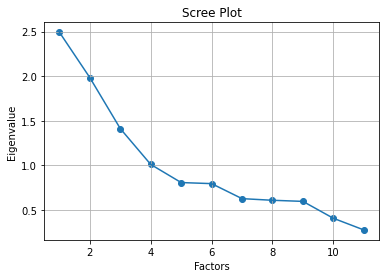

In [40]:
# Create scree plot using matplotlib
from matplotlib import pyplot as plt
# Create scree plot using matplotlib
plt.scatter(range(1,df_cfa.shape[1]+1),ev)
plt.plot(range(1,df_cfa.shape[1]+1),ev)
plt.title('Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.grid()
plt.show()

Остановимся на четырех факторах. Выведем факторные нагрузки для 4-факторного решения

In [41]:
fa = FactorAnalyzer(rotation="varimax", n_factors=4)
fa.fit(df_cfa)
load = fa.loadings_
load

array([[-0.01664394,  0.05020704,  0.75112949,  0.03295251],
       [-0.07041235,  0.21085179,  0.69049528,  0.00283672],
       [ 0.15283408,  0.03686258,  0.07420307,  0.61708751],
       [ 0.29531472, -0.27536722, -0.11227639,  0.38721029],
       [ 0.00617598,  0.50398228,  0.17302041,  0.11669483],
       [-0.03997418,  0.501635  ,  0.15944536, -0.17126545],
       [ 0.88225351, -0.02545091, -0.07301416,  0.14843031],
       [ 0.77843048,  0.04118151, -0.00854933,  0.15091192],
       [ 0.17006228,  0.39947812, -0.06165641, -0.12586437],
       [-0.03618325,  0.59255342,  0.01002275, -0.07768316],
       [-0.09717924,  0.54979977,  0.14736261,  0.156218  ]])

Создадим более наглядную визуализацию 

In [42]:
Film_list = ['Horror', 'Thriller', 'Comedy', 'Romantic', 'Sci', 'War', 'Fantasy', 'Animated', 'Documentary', 'Western', 'Action']

cfa_load = pd.DataFrame(load)
cfa_load['Names'] = Film_list
cfa_load = cfa_load.set_index('Names')

<AxesSubplot:ylabel='Names'>

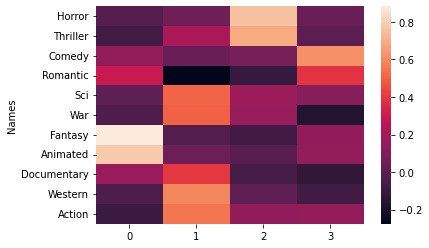

In [43]:
sns.heatmap(cfa_load)

- Первый фактор: Fantasy/Fairy tales, Animated
- Второй фактор: Sci-fi, War, Documentary, Western, Action 
- Третий фактор: Horror, Thriller
- Четвертый фактор: Comedy, Romantic 

## Конфирматорный факторный анализ

С помощью эксплораторного факторного анализа мы выявили гипотетическую факторную структуру наших данных. С помощью конфирматорного факторного анализа проверим, насколько точно эта структура описывает данные 

### Способ 1: factor_analyzer

In [44]:
from factor_analyzer import ConfirmatoryFactorAnalyzer, ModelSpecificationParser

# задаем факторную структуру в виде словаря 
model_dict = {"F1": ["Fantasy", "Animated"],
              "F2": ["Sci", "War", "Documentary", "Western", "Action"], 
             "F3": ["Horror", "Thriller"], 
             "F4": ["Comedy", "Romantic"]} 

#строим модель 
model_spec = ModelSpecificationParser.parse_model_specification_from_dict(df_cfa,                                                                           model_dict)
cfa = ConfirmatoryFactorAnalyzer(model_spec, disp=False)
#применяем модель к данным
cfa.fit(df_cfa.values)
#выводим факторные нагрузки
cfa.loadings_

C:\Users\user\anaconda3\lib\site-packages\factor_analyzer\confirmatory_factor_analyzer.py:753: UserWarning: The optimization routine failed to converge: ABNORMAL_TERMINATION_IN_LNSRCH
  warnings.warn(


array([[1.03683377, 0.        , 0.        , 0.        ],
       [0.81604193, 0.        , 0.        , 0.        ],
       [0.        , 0.20236184, 0.        , 0.        ],
       [0.        , 0.37445953, 0.        , 0.        ],
       [0.        , 0.32890316, 0.        , 0.        ],
       [0.        , 0.09600393, 0.        , 0.        ],
       [0.        , 0.67173564, 0.        , 0.        ],
       [0.        , 0.        , 0.71203607, 0.        ],
       [0.        , 0.        , 0.18320991, 0.        ],
       [0.        , 0.        , 0.        , 0.41358026],
       [0.        , 0.        , 0.        , 0.68489992]])

Существенный недостаток пакета factor_analyzer заключается в том, что он не предполагает рассчет метрик качества модели конфирматорного факторного анализа (TLI, CFI, RMSEA, SRMR). Т.е. мы не можем оценить, насколько хорошо наша модель описывает данные. 

Но по размеру факторных нагрузок мы можем оценить, какие наблюдаемые переменные хорошо вписываются в факторы, а какие - плохо

### Способ 2: Semopy 

Semopy - пакет для проведения путевого анализа (структурного моделирования) в Питоне. Однако с его помощью можно проводить и конфирматорный факторный анализ. Методика рассчета факторных нагрузок у factor_analyzer и Semopy отличаются 

In [122]:
#pip install semopy

In [45]:
from semopy import Model
desc = """    
    # measurement model
    F1 =~ Animated + Fantasy
    F2 =~ War + Documentary + Western + Action + Sci
    F3 =~ Horror + Thriller
    F4 =~ Comedy + Romantic

    """
    
mod = Model(desc)
mod.fit(df_cfa)



SolverResult(fun=0.2672767886218632, success=True, n_it=51, x=array([ 1.22808951,  0.52846999,  0.85989522,  0.91682158,  0.94027538,
        1.51043109,  4.23249413,  1.03122394,  0.64502982,  0.49482451,
        1.09106923,  0.82663962,  0.5352212 , -0.04397095,  0.19787962,
        0.57619376, -0.07420758,  0.06042454,  0.09658514, -0.0610659 ,
       -0.030573  ,  0.1451457 ,  1.34162841,  0.3625708 ,  1.22150589,
        0.08772874,  1.24370873,  0.8390891 ]), message='Optimization terminated successfully', name_method='SLSQP', name_obj='MLW')

Выводим Summary по модели. Обратите анимание, что факторные нагрузки будут отличаться от порядка наблюдаемых переменных (первая переменная в факторе берется за "точку отсчета"). 

In [46]:
mod.inspect()

,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,Animated,~,F1,1.000000,-,-,-
1,Fantasy,~,F1,1.228090,0.116898,10.505687,0.0
2,War,~,F2,1.000000,-,-,-
3,Documentary,~,F2,0.528470,0.080152,6.59338,0.0
4,Western,~,F2,0.859895,0.09473,9.077309,0.0
5,Action,~,F2,0.916822,0.102272,8.964564,0.0
6,Sci,~,F2,0.940275,0.107165,8.774068,0.0
7,Horror,~,F3,1.000000,-,-,-
8,Thriller,~,F3,1.510431,0.295799,5.106281,0.0
9,Comedy,~,F4,1.000000,-,-,-


Выводим метрики качества модели

In [47]:
from semopy import calc_stats
calc_stats(mod)

,DoF,DoF Baseline,chi2,chi2 p-value,chi2 Baseline,CFI,GFI,AGFI,NFI,TLI,RMSEA,AIC,BIC,LogLik
Value,38,55,180.144556,0.0,1470.323678,0.899567,0.87748,0.822668,0.87748,0.854637,0.074553,55.465446,181.83589,0.267277


**Интерпретация метрик качества модели**

- **Chi2** - сравниваются реальная матрица ковариацией и матрица ковариаций, предложенная моделью. Мы хотим, чтобы разница была как можно меньше. Чем меньше Chi2, тем лучше. Этот параметр имеет смысл только при сравнении нескольких моделей. В абсолютных значениях не интерпретируется. 

- **Chi2 p-value** - критерий должен быть значимым, поэтому мы хотим видеть **p<0.05**

- **Chi2 Baseline** - сравниваются реальная матрица ковариаций и нулевая матрица. Обычно принимает большие значения. Для оценки качества модели напрямую не используется

- **GFI (goodness of fit)** - аналог R-квадрат. Рекомендуемое значение **выше 0.9**

- **CFI (comparative fit index)** - этот индекс сравнивает получившуюся модель с гипотетической моделью, в которой нет связи между факторами и наблюдаемыми переменными. Чем значение ближе к 1, тем больше эти модели отличаются. Рекомендованное значение **выше 0.90** (в идеале, выше 0.95)

- **TLI (Tucker-Lewis Index)** - этот индекс по смыслу очень похож на CFI, но чуть более устойчив. Рекомендованное значение **выше 0.90** (в идеале, выше 0.95)

- **RMSEA (Root Mean Square Error of Approximation)** - корень среднего квадрата ошибок аппроксимации. Чем меньше, тем лучше . Рекомендованное значение **меньше 0.08** (в идеале, меньше 0.06)

- **SRMR (Standardized Root Mean Square Residual)** - этой метрики здесь нет. Метрика размеров остатков (т.е. ошибок). Чем меньше, тем лучше. Рекомендованное значение - **меньше 0.08** (в идеале, меньше 0.06) 

- **AIC - Akaike Information Criterion** - измеряет относительное качество статистической модели для заданного набора данных. Он основан на функции правдоподобия и количестве параметров в модели. Чем меньше значение, тем лучше модель. Подходит для сравнения моделей. 

- **BIC - Bayesian Information Criterion** - по смыслу похож на AIC, но более строгий. Чем меньше значение, тем лучше модель. Подходит для сравнения моделей 

- **LogLik - Loglikelihood** - критерий правдоподобия, используется для рассчета AIC и BIC. 

Жанр "Documentary" демонстрирует низкую факторную нагрузку. Удалим его и пересчитаем модель без него

In [48]:
desc = """    
    # measurement model
    F1 =~ Animated + Fantasy
    F2 =~ War + Western + Action + Sci
    F3 =~ Horror + Thriller
    F4 =~ Comedy + Romantic

    """
    
mod = Model(desc)
mod.fit(df_cfa)

SolverResult(fun=0.19159488049147178, success=True, n_it=50, x=array([ 1.25031264,  0.83156374,  0.9765158 ,  1.01240102,  1.45037632,
        4.19846448,  0.99877818,  0.65941618,  0.49442203,  0.81154029,
        0.50607216, -0.06524257,  0.21626466,  0.60032485, -0.07667572,
        0.06111691,  0.09588792, -0.0575989 , -0.03206771,  0.12288387,
        1.31754288,  0.36777424,  1.17619816,  0.13984258,  1.27336975,
        0.88507562]), message='Optimization terminated successfully', name_method='SLSQP', name_obj='MLW')

Качество модели улучшилось 

In [49]:
calc_stats(mod)

,DoF,DoF Baseline,chi2,chi2 p-value,chi2 Baseline,CFI,GFI,AGFI,NFI,TLI,RMSEA,AIC,BIC,LogLik
Value,29,45,129.134949,1.354472e-14,1365.671301,0.924179,0.905442,0.853272,0.905442,0.882346,0.071629,51.61681,168.960793,0.191595


## Путевой анализ (SEM)

Путевой анализ совмещает в себе факторный анализ и регрессию. Он позволяет не только выделить факторы, но и установить взаимосвязь между ними. Например, мы предполагаем, что факторы 1 и 4 будут положительно коррелировать, и факторы 2 и 3 будут положительно коррелировать. Мы можем проверить эту гипотезу при помощи структурного моделирования 

In [56]:
from semopy import Model
desc = """    
    # measurement model
    F1 =~ Animated + Fantasy
    F2 =~ War + Western + Action + Sci
    F3 =~ Horror + Thriller
    F4 =~ Comedy + Romantic
    # regressions
    F1 ~ F4
    F2 ~ F3

    """


    
mod = Model(desc)



In [57]:
mod.fit(df_cfa)

SolverResult(fun=0.22496943030068817, success=True, n_it=45, x=array([ 1.22675641,  0.83969194,  1.00008055,  1.07447337,  1.3441664 ,
        2.99952057,  1.61661267,  0.35563068,  0.99937292,  0.64411266,
        0.47070417,  0.60648512,  0.40027779,  0.64505158,  0.08464407,
       -0.04600933,  0.14644383,  1.27171688,  0.68351126,  1.1386981 ,
        0.2369046 ,  1.29742568,  0.89525798]), message='Optimization terminated successfully', name_method='SLSQP', name_obj='MLW')

In [58]:
mod.inspect()

,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,F1,~,F4,1.616613,0.282903,5.714381,0.0
1,F2,~,F3,0.355631,0.055469,6.411296,0.0
2,Animated,~,F1,1.000000,-,-,-
3,Fantasy,~,F1,1.226756,0.114539,10.710424,0.0
4,War,~,F2,1.000000,-,-,-
5,Western,~,F2,0.839692,0.102331,8.205628,0.0
6,Action,~,F2,1.000081,0.117755,8.492865,0.0
7,Sci,~,F2,1.074473,0.126329,8.505332,0.0
8,Horror,~,F3,1.000000,-,-,-
9,Thriller,~,F3,1.344166,0.212286,6.331876,0.0


In [59]:
from semopy import calc_stats
calc_stats(mod)

,DoF,DoF Baseline,chi2,chi2 p-value,chi2 Baseline,CFI,GFI,AGFI,NFI,TLI,RMSEA,AIC,BIC,LogLik
Value,32,45,151.629396,0.0,1365.671301,0.909418,0.888971,0.843865,0.888971,0.872619,0.074531,45.550061,149.354354,0.224969


Визуализация модели

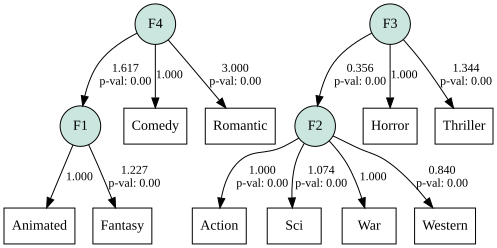

In [61]:
import semopy
g = semopy.semplot(mod, "pd.png")
g

## Задание 2

-  Проведите эксплораторный факторный анализ на одной из групп переменных на выбор (см. описание датасета): (Музыкальные жанры, Хобби, Личные черты)

- Выберете число факторов, определите гипотетическую факторную структуру при помощи факторных нагрузок 

- Проверьте, насколько эта факторная структура подходит к данным, при помощи конфирматорного факторного анализа 

- Попробуйте добиться максимального качества модели (можно не только удалять наблюдаемые переменные, но и приписывать одну переменную нескольким факторам одновременно) 

- Проинтерпретируйте финальную модель 

- Предложите гипотезу о корреляции факторов. Проверьте ее при помощи структурного моделирования. 